# Exploratory data analysis of the Abalone dataset

This notebook explores the structure, quality, distributions, and relationships in the Abalone dataset before modelling the number of shell rings. The analysis keeps the original observations unchanged and creates `Age` only as a derived interpretation of the target.

## Imports and display settings

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")
sns.set_theme(style="whitegrid", context="notebook")

## Load and validate the data

The path works when the notebook is launched either from the repository root or from the `notebooks` directory. The schema check fails early if a different CSV is used by mistake.

In [2]:
data_path = Path("data/abalone.csv")
if not data_path.exists():
    data_path = Path("../data/abalone.csv")

expected_columns = [
    "Sex",
    "Length",
    "Diameter",
    "Height",
    "Whole weight",
    "Shucked weight",
    "Viscera weight",
    "Shell weight",
    "Rings",
]

df = pd.read_csv(data_path)
assert df.columns.tolist() == expected_columns, "Unexpected dataset schema"
print(f"Dataset: {data_path.resolve()}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Dataset: /Users/enfants/Code/xhec-mlops-2026-project/data/abalone.csv
Shape: 4,177 rows x 9 columns


,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.514,0.225,0.101,0.150,15
1,M,0.350,0.265,0.090,0.226,0.100,0.049,0.070,7
2,F,0.530,0.420,0.135,0.677,0.257,0.141,0.210,9
3,M,0.440,0.365,0.125,0.516,0.215,0.114,0.155,10
4,I,0.330,0.255,0.080,0.205,0.089,0.040,0.055,7


## Structure and data quality

In [3]:
quality_summary = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_pct": df.isna().mean().mul(100),
        "unique": df.nunique(),
    }
)
quality_summary

,dtype,missing,missing_pct,unique
Sex,object,0,0.000,3
Length,float64,0,0.000,134
Diameter,float64,0,0.000,111
Height,float64,0,0.000,51
Whole weight,float64,0,0.000,2429
Shucked weight,float64,0,0.000,1515
Viscera weight,float64,0,0.000,880
Shell weight,float64,0,0.000,926
Rings,int64,0,0.000,28


In [4]:
duplicate_count = int(df.duplicated().sum())
invalid_sex_count = int((~df["Sex"].isin(["F", "I", "M"])).sum())
non_positive_measurements = (df.select_dtypes(include=np.number) <= 0).sum()

print(f"Duplicate rows: {duplicate_count}")
print(f"Unexpected Sex values: {invalid_sex_count}")
print("Non-positive numeric values:")
display(non_positive_measurements[non_positive_measurements > 0].to_frame("count"))

Duplicate rows: 0
Unexpected Sex values: 0
Non-positive numeric values:


,count
Height,2


The dataset has no missing or duplicate rows. Two observations have a height of zero, which is physically implausible. Very large height values also deserve review before modelling. They are flagged below rather than removed, so the raw data remains intact.

In [5]:
height_flags = df.loc[(df["Height"] <= 0) | (df["Height"] > 0.30)].copy()
height_flags

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
1257,I,0.430,0.340,0.000,0.428,0.206,0.086,0.115,8
1417,M,0.705,0.565,0.515,2.210,1.107,0.486,0.512,10
2051,F,0.455,0.355,1.130,0.594,0.332,0.116,0.134,8
3996,I,0.315,0.230,0.000,0.134,0.058,0.029,0.350,6


## Descriptive statistics

Abalone age is commonly approximated as the number of rings plus 1.5 years. `Age` is therefore derived from `Rings` and must never be used as an input feature when predicting `Rings`, because that would create target leakage.

In [6]:
eda_df = df.assign(Age=df["Rings"] + 1.5)
eda_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Length,4177.000,0.524,0.120,0.075,0.450,0.545,0.615,0.815
Diameter,4177.000,0.408,0.099,0.055,0.350,0.425,0.480,0.650
Height,4177.000,0.140,0.042,0.000,0.115,0.140,0.165,1.130
Whole weight,4177.000,0.829,0.490,0.002,0.442,0.799,1.153,2.825
Shucked weight,4177.000,0.359,0.222,0.001,0.186,0.336,0.502,1.488
Viscera weight,4177.000,0.181,0.110,0.001,0.093,0.171,0.253,0.760
Shell weight,4177.000,0.239,0.139,0.002,0.130,0.234,0.329,1.005
Rings,4177.000,9.934,3.224,1.000,8.000,9.000,11.000,29.000
Age,4177.000,11.434,3.224,2.500,9.500,10.500,12.500,30.500


## Target distribution

,Rings
count,4177.000
mean,9.934
std,3.224
min,1.000
5%,6.000
25%,8.000
50%,9.000
75%,11.000
95%,16.000
99%,20.000


/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):


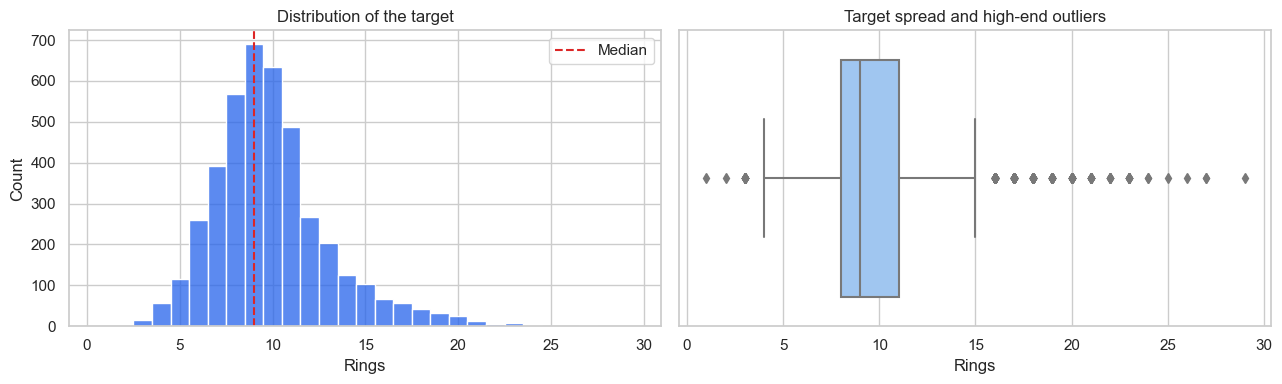

In [7]:
rings_summary = eda_df["Rings"].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
display(rings_summary.to_frame("Rings"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=eda_df, x="Rings", bins=29, discrete=True, ax=axes[0], color="#2563EB")
axes[0].axvline(eda_df["Rings"].median(), color="#DC2626", linestyle="--", label="Median")
axes[0].set_title("Distribution of the target")
axes[0].legend()
sns.boxplot(data=eda_df, x="Rings", ax=axes[1], color="#93C5FD")
axes[1].set_title("Target spread and high-end outliers")
plt.tight_layout()
plt.show()

`Rings` is concentrated around 8 to 11 and has a longer right tail. A model evaluated only with RMSE may be strongly affected by the relatively rare older abalones, so MAE should also be reported.

## Numeric feature distributions

/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWar

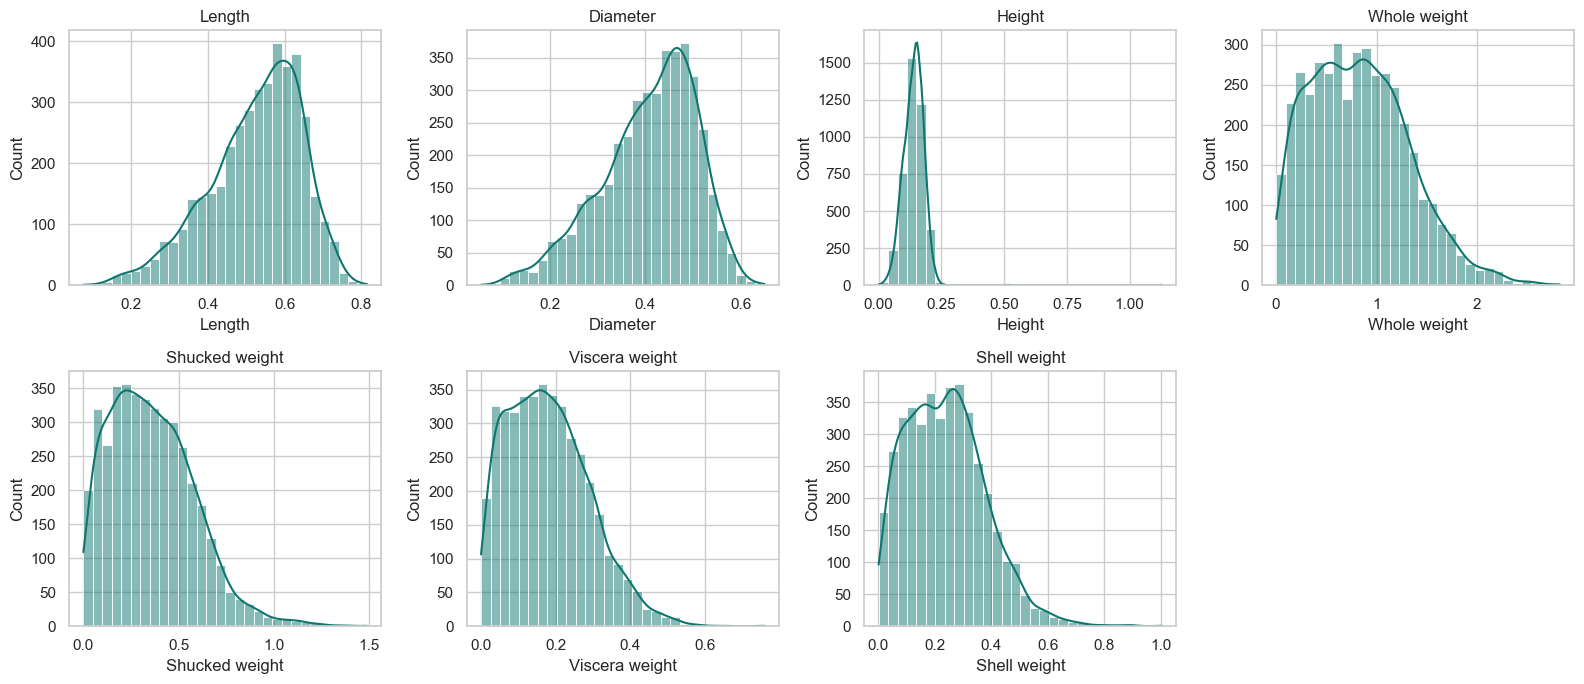

In [8]:
numeric_features = [column for column in expected_columns if column not in {"Sex", "Rings"}]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, column in zip(axes.flat, numeric_features):
    sns.histplot(data=eda_df, x=column, bins=30, kde=True, ax=ax, color="#0F766E")
    ax.set_title(column)
for ax in axes.flat[len(numeric_features) :]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

The size and weight variables are right-skewed because the dataset contains many small or infant abalones and fewer very large specimens. Standardization will help linear and distance-based models, while tree-based models are less sensitive to feature scale.

## Sex category and target

,observations,mean_rings,median_rings,mean_whole_weight
Sex,,,,
F,1307,11.129,10.000,1.047
I,1342,7.890,8.000,0.431
M,1528,10.705,10.000,0.991


/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_c

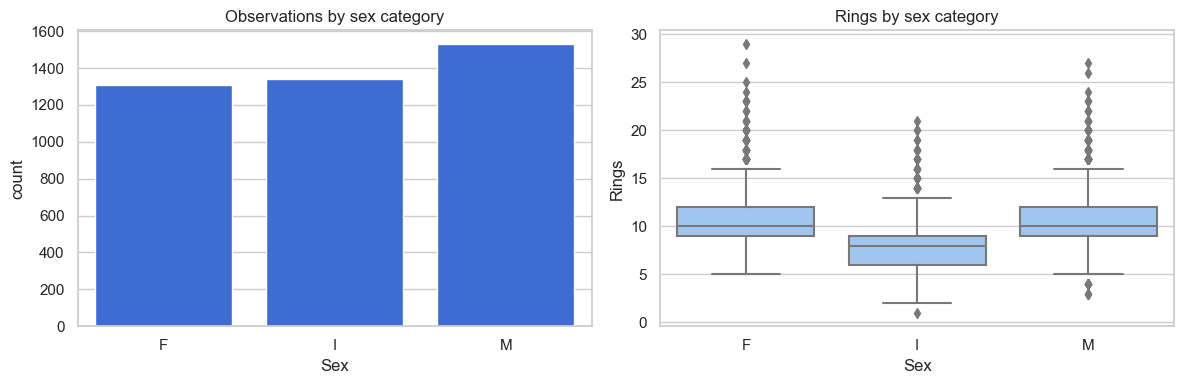

In [9]:
sex_summary = (
    eda_df.groupby("Sex", observed=True)
    .agg(
        observations=("Rings", "size"),
        mean_rings=("Rings", "mean"),
        median_rings=("Rings", "median"),
        mean_whole_weight=("Whole weight", "mean"),
    )
    .round(3)
)
display(sex_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=eda_df, x="Sex", order=["F", "I", "M"], ax=axes[0], color="#2563EB")
axes[0].set_title("Observations by sex category")
sns.boxplot(data=eda_df, x="Sex", y="Rings", order=["F", "I", "M"], ax=axes[1], color="#93C5FD")
axes[1].set_title("Rings by sex category")
plt.tight_layout()
plt.show()

The categories are reasonably balanced. Infant (`I`) abalones have fewer rings on average and are also lighter, so the observed group difference should not be interpreted as an isolated causal effect of sex. `Sex` will require categorical encoding for modelling.

## Relationships with the target

/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_c

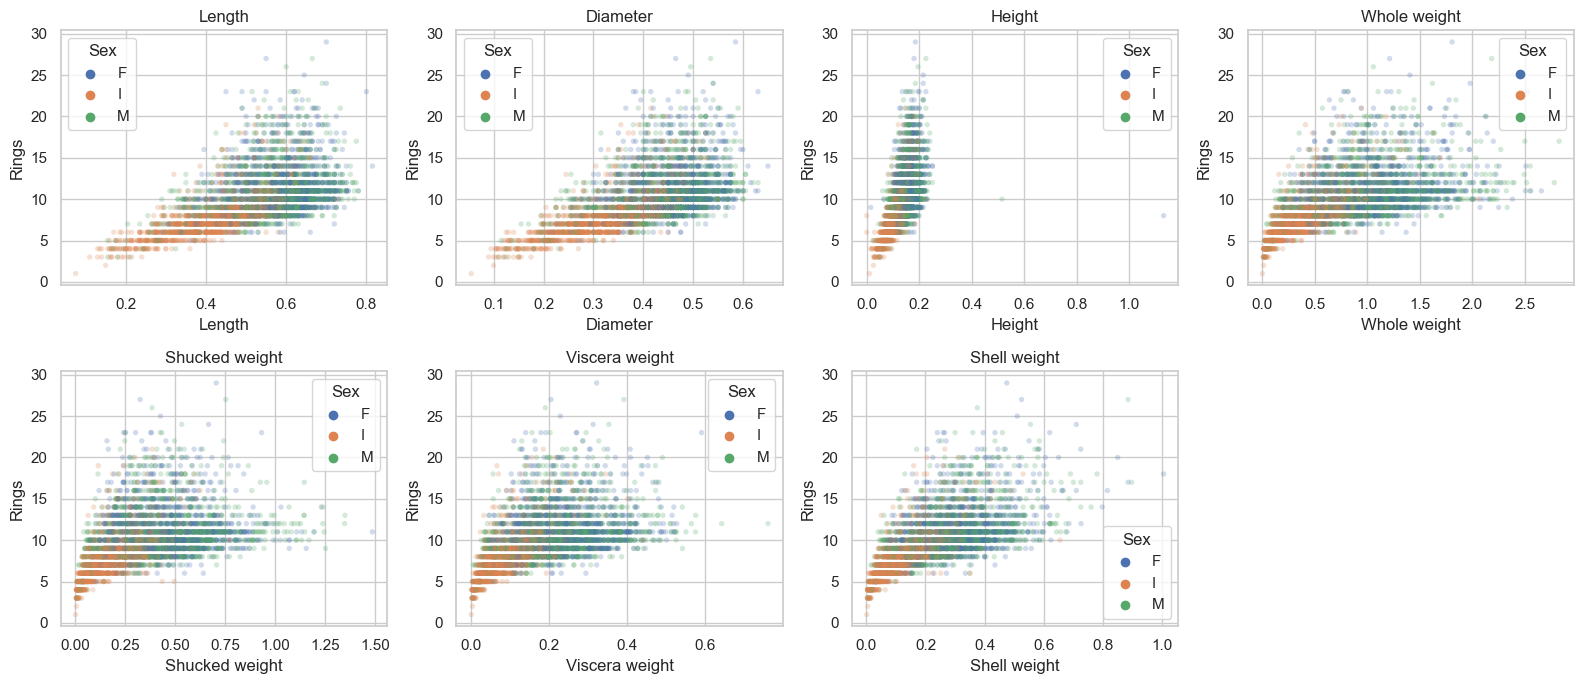

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, column in zip(axes.flat, numeric_features):
    sns.scatterplot(
        data=eda_df,
        x=column,
        y="Rings",
        hue="Sex",
        hue_order=["F", "I", "M"],
        alpha=0.25,
        s=15,
        linewidth=0,
        legend=True,
        ax=ax,
    )
    ax.set_title(column)
for ax in axes.flat[len(numeric_features) :]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

All physical measurements have a positive relationship with `Rings`, but the spread grows for larger abalones and the relationship is not strictly linear. This supports comparing a linear baseline with a nonlinear tree-based model.

## Correlations and multicollinearity

,correlation_with_rings
Shell weight,0.628
Diameter,0.575
Height,0.557
Length,0.557
Whole weight,0.540
Viscera weight,0.504
Shucked weight,0.421


/Users/enfants/Code/xhec-mlops-2026-project/.venv/lib/python3.11/site-packages/seaborn/matrix.py:260: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  annotation = ("{:" + self.fmt + "}").format(val)


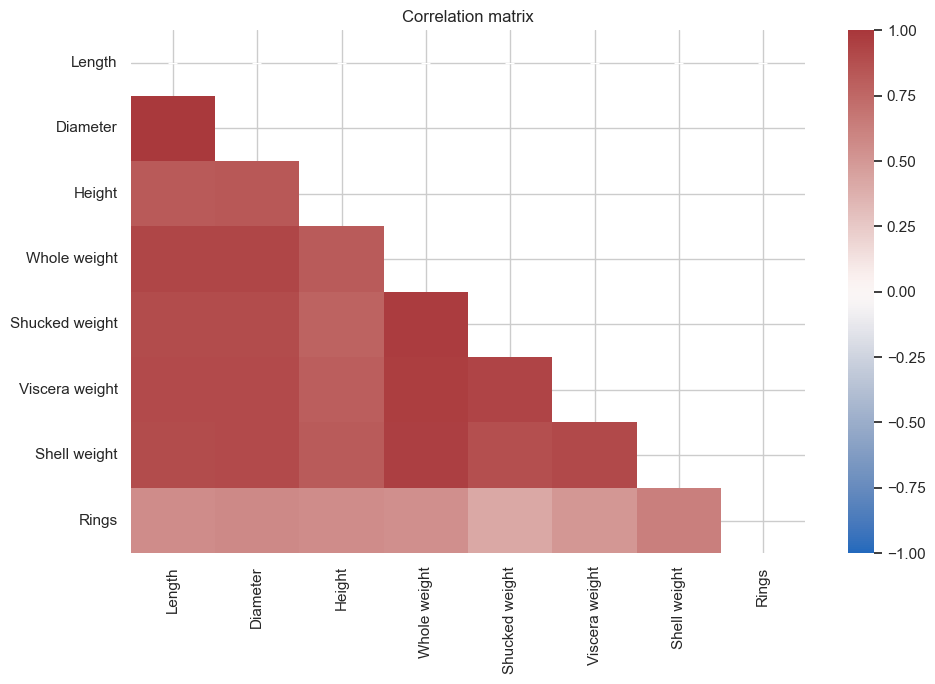

In [11]:
correlation_matrix = eda_df.drop(columns="Age").corr(numeric_only=True)
target_correlations = correlation_matrix["Rings"].drop("Rings").sort_values(ascending=False)
display(target_correlations.to_frame("correlation_with_rings"))

plt.figure(figsize=(10, 7))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

`Shell weight` has the strongest individual linear correlation with `Rings`. Most size and weight features are also highly correlated with each other, especially length with diameter and whole weight with its component weights. Coefficients from an unregularized linear model may therefore be unstable even when predictive performance is acceptable.

## IQR-based outlier review

The IQR rule is used only to flag observations for review. Extreme values may represent valid old or large abalones, so they should not be removed without domain justification.

**What is the IQR?** The interquartile range is the spread of the middle 50% of the data: `IQR = Q3 - Q1`, where Q1 is the 25th percentile and Q3 the 75th percentile.

**The rule.** A value is flagged as an outlier if it is outside these bounds:

- lower bound = `Q1 - 1.5 * IQR`
- upper bound = `Q3 + 1.5 * IQR`

This is the same rule used to draw the whiskers of a boxplot.

**How to read the table below.** For each feature, `lower_bound` and `upper_bound` are the limits, `outlier_count` is the number of rows outside them and `outlier_pct` is that count as a percentage of all rows. A high percentage is a reason to look at the data, not a reason to delete it.

In [12]:
outlier_rows = []
for column in numeric_features + ["Rings"]:
    q1, q3 = eda_df[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = int(((eda_df[column] < lower_bound) | (eda_df[column] > upper_bound)).sum())
    outlier_rows.append(
        {
            "feature": column,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": outlier_count,
            "outlier_pct": 100 * outlier_count / len(eda_df),
        }
    )

outlier_summary = pd.DataFrame(outlier_rows).set_index("feature").round(3)
outlier_summary

,lower_bound,upper_bound,outlier_count,outlier_pct
feature,,,,
Length,0.203,0.862,49,1.173
Diameter,0.155,0.675,59,1.412
Height,0.040,0.240,29,0.694
Whole weight,-0.626,2.220,30,0.718
Shucked weight,-0.288,0.976,48,1.149
Viscera weight,-0.146,0.492,26,0.622
Shell weight,-0.168,0.628,35,0.838
Rings,3.500,15.500,278,6.655


## Conclusions and modelling implications

- The dataset contains 4,177 observations, eight predictors, and the `Rings` target. No missing or duplicate rows were found.
- Two zero heights and two unusually large heights require review. They remain in the raw data at this stage.

<br>

- `Rings` is right-skewed, with most observations between 8 and 11. MAE and RMSE should both be reported because RMSE gives more weight to errors on older abalones.

<br>

- Infant abalones have fewer rings and lower weight on average. `Sex` should be one-hot encoded, while group differences should not be interpreted causally.
- `Shell weight` is the strongest single linear correlate of `Rings`. Physical measurements are strongly correlated with each other, which creates multicollinearity.
- The feature-target relationships show nonlinearity and changing variance. The modelling notebook should compare a regularized linear baseline with at least one tree-based regressor.

<br>

- `Age` is derived directly from `Rings` and must not be included among the model inputs.